# 05 — Final Numerical Comparison of Iterative Solvers and Preconditioners

## 1. Objective and Experimental Setup

### Objective

In this notebook, I will compare the numerical performance of the iterative solvers and preconditioning approaches studied in my previous four notebooks.

My goal is to understand how the different methods behave in terms of convergence, iteration counts, and computational cost.

### Methods to Compare

- Direct solver as a reference solution.
- MINRES and GMRES without preconditioning.
- Exact block diagonal Schur complement preconditioning.
- Exact block triangular Schur complement preconditioning with GMRES.
- Approximate block diagonal Schur complement preconditioning.
- Artificial compressibility iterative correction method.

### Comparison Conditions

I will use the same two-dimensional mixed Darcy problem with unit permeability and RT0–P0 finite elements.

I will test three mesh sizes:

- 4 × 4
- 8 × 8
- 16 × 16

For iterative methods, I will use a common actual relative residual target of 10⁻⁸:


$$
\frac{\|b-Gz_k\|_2}{\|b\|_2} \leq 10^{-8}
$$

I will evaluate the residual using the original saddle-point system.

I will also distinguish setup time from solve time when analyzing computational costs.

### Important Consideration

My previous notebooks used different residual targets and factorization methods. Therefore, I will not treat their existing timings as a directly fair performance comparison.

I will use consistent experimental conditions where possible and clearly discuss any remaining differences.

In [31]:
%pip -q install scikit-fem

import numpy as np
import pandas as pd
import scipy
import matplotlib
import skfem

from scipy.sparse import bmat, eye, diags
from scipy.sparse.linalg import (
    spsolve, splu, minres, gmres, LinearOperator
)

from skfem import (
    MeshTri, Basis, ElementTriRT0, ElementTriP0,
    BilinearForm, LinearForm, asm
)
from skfem.helpers import dot, div

import time

mesh_sizes = [4, 8, 16]
target_residual = 1e-8

print("Notebook 05: Final Numerical Comparison")
print("---------------------------------------")
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("scikit-fem version:", skfem.__version__)
print("Mesh sizes:", mesh_sizes)
print("Common residual target:", target_residual)
print("Environment setup completed.")

Note: you may need to restart the kernel to use updated packages.
Notebook 05: Final Numerical Comparison
---------------------------------------
NumPy version: 2.1.3
SciPy version: 1.16.3
scikit-fem version: 12.0.2
Mesh sizes: [4, 8, 16]
Common residual target: 1e-08
Environment setup completed.


### Result

I successfully set up the Python environment for my final numerical comparison study.

I imported NumPy, SciPy, Pandas, Matplotlib, and scikit-fem.

The installed versions of the main numerical libraries are:

- NumPy: 2.1.3
- SciPy: 1.16.3
- scikit-fem: 12.0.2

I selected three mesh sizes: 4 × 4, 8 × 8, and 16 × 16.

I also defined a common actual relative residual target of 10⁻⁸ for comparing the iterative methods.

The environment setup completed successfully without errors.

No numerical solver experiments were performed in this step.


## 2. Darcy System Assembly and Direct Reference Solutions

### Objective

In this step, I assemble the same two-dimensional mixed Darcy saddle-point system for three different mesh sizes.

I use RT0 finite elements for flux and P0 elements for pressure.

The problem is defined on the unit square with constant permeability K = 1 and homogeneous pressure boundary conditions.

For the numerical experiment, I use:

$$
p(x,y)=\sin(\pi x)\sin(\pi y)
$$

and the corresponding source term:

$$
f(x,y)=2\pi^2\sin(\pi x)\sin(\pi y)
$$

The discrete system has the form:

$$
G=
\begin{bmatrix}
A & -D^T \\
-D & 0
\end{bmatrix}
$$

with the right-hand side:

$$
b=
\begin{bmatrix}
0 \\
-F
\end{bmatrix}
$$

I will assemble this system on the 4 × 4, 8 × 8, and 16 × 16 meshes.

I will then compute a direct reference solution for each mesh and check the actual relative residual.

These assembled systems and reference solutions will be reused in the solver comparison experiments.


In [32]:
# Step 2: Darcy system assembly and direct reference solutions

@BilinearForm
def flux_mass_form(q, v, w):
    return dot(q, v)


@BilinearForm
def divergence_form(q, r, w):
    return div(q) * r


@LinearForm
def source_form(r, w):
    x, y = w.x[0], w.x[1]
    return (
        2 * np.pi**2
        * np.sin(np.pi * x)
        * np.sin(np.pi * y)
        * r
    )


def build_darcy_system(n):
    # Create triangular mesh
    points = np.linspace(0.0, 1.0, n + 1)
    mesh = MeshTri.init_tensor(points, points)

    # RT0 flux and P0 pressure spaces
    flux_basis = Basis(mesh, ElementTriRT0(), intorder=2)
    pressure_basis = Basis(mesh, ElementTriP0(), intorder=2)

    # Assemble the finite element matrices
    A = asm(flux_mass_form, flux_basis).tocsr()

    D = asm(
        divergence_form,
        flux_basis,
        pressure_basis
    ).tocsr()

    F = asm(source_form, pressure_basis)

    # Original saddle-point system
    G = bmat(
        [
            [A, -D.T],
            [-D, None]
        ],
        format="csr"
    )

    b = np.concatenate([
        np.zeros(flux_basis.N),
        -F
    ])

    # Direct reference solution
    z_direct = spsolve(G, b)

    # Actual residual of the original system
    relative_residual = (
        np.linalg.norm(b - G @ z_direct)
        / np.linalg.norm(b)
    )

    return {
        "A": A,
        "D": D,
        "G": G,
        "b": b,
        "z_direct": z_direct,
        "triangles": mesh.nelements,
        "flux_dofs": flux_basis.N,
        "pressure_dofs": pressure_basis.N,
        "total_dofs": G.shape[0],
        "direct_residual": relative_residual
    }


# Assemble and store all three systems
darcy_systems = {}
assembly_results = []

for n in mesh_sizes:
    system = build_darcy_system(n)
    darcy_systems[n] = system

    assembly_results.append({
        "Mesh": f"{n} x {n}",
        "Triangles": system["triangles"],
        "Flux DOFs": system["flux_dofs"],
        "Pressure DOFs": system["pressure_dofs"],
        "Total DOFs": system["total_dofs"],
        "Direct residual": system["direct_residual"]
    })


assembly_df = pd.DataFrame(assembly_results)

print("Darcy System Assembly and Direct Solutions")
print("------------------------------------------")

display(
    assembly_df.style
    .hide(axis="index")
    .format({
        "Direct residual": "{:.6e}"
    })
)

# Verify the expected system dimensions
expected_dofs = {4: 88, 8: 336, 16: 1312}

for n in mesh_sizes:
    assert darcy_systems[n]["total_dofs"] == expected_dofs[n]
    assert darcy_systems[n]["direct_residual"] < target_residual

print("\nAll system dimensions are correct.")
print("All direct solutions satisfy the residual target.")

Darcy System Assembly and Direct Solutions
------------------------------------------


Mesh,Triangles,Flux DOFs,Pressure DOFs,Total DOFs,Direct residual
4 x 4,32,56,32,88,7.443571e-16
8 x 8,128,208,128,336,2.360333e-15
16 x 16,512,800,512,1312,9.843011e-15



All system dimensions are correct.
All direct solutions satisfy the residual target.


### Result

I successfully assembled the mixed Darcy saddle-point system for three different mesh sizes.

I used RT0 finite elements for flux and P0 elements for pressure.

The assembled systems had the following dimensions:

| Mesh Size | Triangles | Flux DOFs | Pressure DOFs | Total DOFs |
|---|---:|---:|---:|---:|
| 4 × 4 | 32 | 56 | 32 | 88 |
| 8 × 8 | 128 | 208 | 128 | 336 |
| 16 × 16 | 512 | 800 | 512 | 1312 |

I solved each system using SciPy's direct solver and calculated the actual relative residual of the original saddle-point system.

The measured relative residuals were:

- 4 × 4 mesh: 7.443571 × 10⁻¹⁶
- 8 × 8 mesh: 2.360333 × 10⁻¹⁵
- 16 × 16 mesh: 9.843011 × 10⁻¹⁵

All three direct solutions satisfied my common residual target of 10⁻⁸.

The system dimensions also matched the expected values.

I will use these assembled matrices and direct solutions as references when comparing the iterative solvers and preconditioning methods in the next experiments.


## 3. Baseline Comparison: MINRES and GMRES

### Objective

In this step, I compare MINRES and GMRES without preconditioning.

I use the same three Darcy systems assembled in Step 2.

Both methods solve the original saddle-point system:

$$
Gz=b
$$

### Comparison Criteria

For each solver and mesh size, I will record:

- Number of iterations.
- Actual relative residual.
- Relative difference from the direct reference solution.
- Internal solver tolerance.
- Solver completion status.

My common actual relative residual target is:

$$
\frac{\|b-Gz_k\|_2}{\|b\|_2}
\leq 10^{-8}
$$

I will calculate this residual independently rather than relying only on the solver's completion status.

### Solver Tolerance Consideration

I will initially use an internal relative tolerance of 10⁻⁸.

If a solver finishes without reaching my independently checked residual target, I will try a tighter internal tolerance.

I will record the tolerance used for the accepted result.

This means that the internal stopping tolerances may differ, even though every accepted solution must satisfy the same actual residual target.

These results will provide the unpreconditioned baseline for my later comparisons.


In [33]:
# Step 3: MINRES and GMRES without preconditioning

baseline_results = []
baseline_solutions = {}

# Try a tighter internal tolerance only if needed
rtol_options = [1e-8, 1e-10, 1e-12]


def run_baseline_solver(G, b, method, target):
    b_norm = np.linalg.norm(b)

    for internal_rtol in rtol_options:
        iteration_count = [0]

        def count_iteration(value):
            iteration_count[0] += 1

        if method == "MINRES":
            z, info = minres(
                G,
                b,
                rtol=internal_rtol,
                maxiter=5000,
                callback=count_iteration
            )

        elif method == "GMRES":
            z, info = gmres(
                G,
                b,
                rtol=internal_rtol,
                atol=0.0,
                restart=20,
                maxiter=500,
                callback=count_iteration,
                callback_type="pr_norm"
            )

        else:
            raise ValueError("Unknown solver.")

        # Independently check the original system
        actual_residual = (
            np.linalg.norm(b - G @ z) / b_norm
        )

        # Accept only a successful solve that meets our target
        if info == 0 and actual_residual <= target:
            return {
                "solution": z,
                "iterations": iteration_count[0],
                "internal_rtol": internal_rtol,
                "actual_residual": actual_residual,
                "info": info,
                "target_met": True
            }

    # Stop if none of the tested tolerances worked
    raise RuntimeError(
        f"{method} did not meet the target. "
        f"Last residual: {actual_residual:.3e}, "
        f"last info: {info}"
    )


for n in mesh_sizes:
    system = darcy_systems[n]

    G = system["G"]
    b = system["b"]
    z_direct = system["z_direct"]

    for method in ["MINRES", "GMRES"]:
        result = run_baseline_solver(
            G,
            b,
            method,
            target_residual
        )

        z = result["solution"]

        relative_solution_error = (
            np.linalg.norm(z - z_direct)
            / np.linalg.norm(z_direct)
        )

        baseline_solutions[(n, method)] = z

        baseline_results.append({
            "Mesh": f"{n} x {n}",
            "DOFs": system["total_dofs"],
            "Solver": method,
            "Iterations": result["iterations"],
            "Internal rtol": result["internal_rtol"],
            "Actual residual": result["actual_residual"],
            "Relative solution error": relative_solution_error,
            "Info": result["info"],
            "Target met": result["target_met"]
        })


baseline_df = pd.DataFrame(baseline_results)

print("MINRES and GMRES Baseline Comparison")
print("---------------------------------------")

display(
    baseline_df.style
    .hide(axis="index")
    .format({
        "Internal rtol": "{:.0e}",
        "Actual residual": "{:.6e}",
        "Relative solution error": "{:.6e}"
    })
)

assert baseline_df["Target met"].all()
assert (baseline_df["Actual residual"] <= target_residual).all()
assert (baseline_df["Info"] == 0).all()

print("\nAll baseline solver results satisfy the target.")

MINRES and GMRES Baseline Comparison
---------------------------------------


Mesh,DOFs,Solver,Iterations,Internal rtol,Actual residual,Relative solution error,Info,Target met
4 x 4,88,MINRES,24,1e-08,4.182250e-14,7.288251e-15,0,True
4 x 4,88,GMRES,72,1e-08,7.562057e-09,5.134941e-09,0,True
8 x 8,336,MINRES,88,1e-12,6.122140e-11,1.507427e-11,0,True
8 x 8,336,GMRES,289,1e-08,9.562787e-09,8.616628e-09,0,True
16 x 16,1312,MINRES,173,1e-12,5.088659e-10,3.271072e-11,0,True
16 x 16,1312,GMRES,791,1e-08,9.823879e-09,9.416685e-09,0,True



All baseline solver results satisfy the target.


### Result

I successfully tested MINRES and GMRES without preconditioning on three different mesh sizes.

I used the same Darcy saddle-point systems and a common actual relative residual target of 10⁻⁸.

The iteration counts were:

| Mesh Size | MINRES | GMRES |
|---|---:|---:|
| 4 × 4 | 24 | 72 |
| 8 × 8 | 88 | 289 |
| 16 × 16 | 173 | 791 |

All six solver configurations reached the actual relative residual target, and each solver returned a successful completion status.

I observed that MINRES required fewer iterations than GMRES on all three tested meshes.

The iteration counts increased with mesh refinement for both methods.

For the 16 × 16 mesh with 1312 unknowns, MINRES required 173 iterations, while GMRES required 791 iterations.

I also compared the iterative solutions with the direct reference solutions. The relative solution differences were small for all six configurations.

### Solver Tolerance Observation

For MINRES, I used an internal tolerance of 10⁻⁸ on the smallest mesh. On the two larger meshes, I needed a tighter internal tolerance of 10⁻¹² to satisfy my independently checked residual target.

GMRES reached the actual residual target using an internal tolerance of 10⁻⁸ for all three meshes.

I used GMRES with a restart value of 20 in this experiment. Its iteration counts differ from those recorded in Notebook 2, so I will keep this configuration difference in mind when interpreting the results.

These experiments provide my unpreconditioned baseline for comparing the preconditioning methods in the next steps.

The iteration counts describe convergence behavior, but they do not directly measure total computational cost.


## 4. Exact Block Diagonal Schur Complement Preconditioning

### Objective

In this step, I apply an exact block diagonal Schur complement preconditioner to MINRES and GMRES.

I want to compare the preconditioned iteration counts with the unpreconditioned baseline obtained in Step 3.

### Mathematical Formulation

For the Darcy saddle-point matrix,

$$
G=
\begin{bmatrix}
A & -D^T \\
-D & 0
\end{bmatrix}
$$

the exact Schur complement is:

$$
S=DA^{-1}D^T
$$

I construct the block diagonal preconditioner:

$$
P=
\begin{bmatrix}
A & 0 \\
0 & S
\end{bmatrix}
$$

I use the inverse action of this preconditioner inside the iterative solvers.

### Implementation

I use dense Cholesky factorization to apply the inverse actions of A and S.

I construct the preconditioner once for each mesh and use it with both MINRES and GMRES.

I will compare:

- Iteration counts with and without preconditioning.
- Actual relative residuals.
- Relative differences from the direct reference solutions.
- Internal solver tolerances.
- Iteration reduction percentages.

I use the same three mesh sizes and the common actual relative residual target of 10⁻⁸.

I will evaluate the residual using the original Darcy system.

This step focuses on convergence. I will study preconditioner setup and solve costs separately later.


In [34]:
# Step 4: Exact block diagonal Schur complement preconditioner

from scipy.linalg import cho_factor, cho_solve


def build_exact_diagonal_preconditioner(A, D):
    # Convert the required matrices to dense form
    A_dense = A.toarray()
    D_dense = D.toarray()

    # Cholesky factorization of A
    A_factor = cho_factor(
        A_dense,
        lower=True,
        check_finite=False
    )

    # Exact Schur complement: S = D A^(-1) D^T
    A_inv_D_T = cho_solve(
        A_factor,
        D_dense.T,
        check_finite=False
    )

    S = D_dense @ A_inv_D_T

    # Remove small numerical asymmetry
    S = 0.5 * (S + S.T)

    # Cholesky factorization of S
    S_factor = cho_factor(
        S,
        lower=True,
        check_finite=False
    )

    flux_dofs = A.shape[0]
    total_dofs = flux_dofs + D.shape[0]

    # Apply P^(-1) to a vector
    def apply_preconditioner(v):
        v_flux = v[:flux_dofs]
        v_pressure = v[flux_dofs:]

        z_flux = cho_solve(
            A_factor,
            v_flux,
            check_finite=False
        )

        z_pressure = cho_solve(
            S_factor,
            v_pressure,
            check_finite=False
        )

        return np.concatenate([z_flux, z_pressure])

    return LinearOperator(
        (total_dofs, total_dofs),
        matvec=apply_preconditioner,
        dtype=np.float64
    )


def run_exact_diagonal_solver(G, b, M_inv, method):
    b_norm = np.linalg.norm(b)

    for internal_rtol in [1e-8, 1e-10, 1e-12]:
        iteration_count = [0]

        def count_iteration(value):
            iteration_count[0] += 1

        if method == "MINRES":
            z, info = minres(
                G,
                b,
                M=M_inv,
                rtol=internal_rtol,
                maxiter=5000,
                callback=count_iteration
            )

        elif method == "GMRES":
            z, info = gmres(
                G,
                b,
                M=M_inv,
                rtol=internal_rtol,
                atol=0.0,
                restart=20,
                maxiter=500,
                callback=count_iteration,
                callback_type="pr_norm"
            )

        else:
            raise ValueError("Unknown solver")

        actual_residual = (
            np.linalg.norm(b - G @ z) / b_norm
        )

        if info == 0 and actual_residual <= target_residual:
            return {
                "solution": z,
                "iterations": iteration_count[0],
                "internal_rtol": internal_rtol,
                "actual_residual": actual_residual,
                "info": info,
                "target_met": True
            }

    raise RuntimeError(
        f"{method} did not reach the actual residual target. "
        f"Last residual: {actual_residual:.3e}"
    )


exact_diag_results = []
exact_diag_solutions = {}

for n in mesh_sizes:
    system = darcy_systems[n]

    A = system["A"]
    D = system["D"]
    G = system["G"]
    b = system["b"]
    z_direct = system["z_direct"]

    # Build the preconditioner once per mesh
    M_inv = build_exact_diagonal_preconditioner(A, D)

    for method in ["MINRES", "GMRES"]:
        result = run_exact_diagonal_solver(
            G, b, M_inv, method
        )

        z = result["solution"]

        relative_solution_error = (
            np.linalg.norm(z - z_direct)
            / np.linalg.norm(z_direct)
        )

        # Get the corresponding unpreconditioned result
        baseline_row = baseline_df[
            (baseline_df["Mesh"] == f"{n} x {n}")
            & (baseline_df["Solver"] == method)
        ].iloc[0]

        baseline_iterations = int(
            baseline_row["Iterations"]
        )

        iteration_reduction = (
            100.0
            * (baseline_iterations - result["iterations"])
            / baseline_iterations
        )

        exact_diag_solutions[(n, method)] = z

        exact_diag_results.append({
            "Mesh": f"{n} x {n}",
            "Solver": method,
            "Baseline iterations": baseline_iterations,
            "Preconditioned iterations": result["iterations"],
            "Reduction (%)": iteration_reduction,
            "Internal rtol": result["internal_rtol"],
            "Actual residual": result["actual_residual"],
            "Relative solution error": relative_solution_error,
            "Info": result["info"],
            "Target met": result["target_met"]
        })


exact_diag_df = pd.DataFrame(exact_diag_results)

print("Exact Block Diagonal Preconditioner Comparison")
print("----------------------------------------------")

display(
    exact_diag_df.style
    .hide(axis="index")
    .format({
        "Reduction (%)": "{:.2f}",
        "Internal rtol": "{:.0e}",
        "Actual residual": "{:.6e}",
        "Relative solution error": "{:.6e}"
    })
)

# Check all results
assert len(exact_diag_df) == 6
assert exact_diag_df["Target met"].all()
assert (exact_diag_df["Actual residual"] <= target_residual).all()
assert (exact_diag_df["Info"] == 0).all()

print("\nAll preconditioned results satisfy the target.")

Exact Block Diagonal Preconditioner Comparison
----------------------------------------------


Mesh,Solver,Baseline iterations,Preconditioned iterations,Reduction (%),Internal rtol,Actual residual,Relative solution error,Info,Target met
4 x 4,MINRES,24,2,91.67,1e-08,1.528504e-15,8.380601e-16,0,True
4 x 4,GMRES,72,2,97.22,1e-08,2.123968e-15,6.297244e-16,0,True
8 x 8,MINRES,88,2,97.73,1e-08,8.247999e-15,1.109109e-15,0,True
8 x 8,GMRES,289,2,99.31,1e-08,8.188814e-15,1.087911e-15,0,True
16 x 16,MINRES,173,2,98.84,1e-08,3.279877e-14,2.117225e-15,0,True
16 x 16,GMRES,791,2,99.75,1e-08,3.482850e-14,2.178336e-15,0,True



All preconditioned results satisfy the target.


### Result

I successfully implemented the exact block diagonal Schur complement preconditioner and tested it with MINRES and GMRES.

I used the same three Darcy systems and the common actual relative residual target of 10⁻⁸.

### Iteration Comparison

| Mesh Size | Solver | Without Preconditioning | With Preconditioning | Iteration Reduction |
|---|---|---:|---:|---:|
| 4 × 4 | MINRES | 24 | 2 | 91.67% |
| 4 × 4 | GMRES | 72 | 2 | 97.22% |
| 8 × 8 | MINRES | 88 | 2 | 97.73% |
| 8 × 8 | GMRES | 289 | 2 | 99.31% |
| 16 × 16 | MINRES | 173 | 2 | 98.84% |
| 16 × 16 | GMRES | 791 | 2 | 99.75% |

I observed that both solvers required only 2 iterations for all three tested meshes when using the exact block diagonal preconditioner.

All six configurations reached the actual relative residual target of 10⁻⁸.

The solver completion status was successful in every case, and the relative differences from the direct reference solutions were very small.

I also observed that the preconditioned solvers reached the target using an internal tolerance of 10⁻⁸ for all three meshes.

### Main Observation

The exact block diagonal preconditioner greatly reduced the iteration counts compared with the unpreconditioned baseline.

The iteration count remained at 2 even when the system size increased from 88 to 1312 unknowns.

This shows that the exact Schur complement preconditioner was very effective at reducing iterations for my tested Darcy systems.

However, constructing the exact Schur complement and performing dense Cholesky factorizations also require computational work.

Therefore, I cannot conclude that this method has the lowest total computation time based only on iteration counts.

I will examine setup and solve costs separately in the later comparison experiments.

## 5. Exact Block Triangular Schur Complement Preconditioning

### Objective

In this step, I implement the exact block triangular Schur complement preconditioner and test it with GMRES.

I want to compare its convergence with unpreconditioned GMRES and the exact block diagonal preconditioner.

### Mathematical Formulation

The original Darcy saddle-point matrix is:

$$
G=
\begin{bmatrix}
A & -D^T \\
-D & 0
\end{bmatrix}
$$

The exact Schur complement is:

$$
S=DA^{-1}D^T
$$

I construct the block triangular preconditioner:

$$
P_T=
\begin{bmatrix}
A & 0 \\
-D & -S
\end{bmatrix}
$$

The preconditioner is applied by solving:

$$
P_T y=v
$$

I first solve for the flux component and then use it to calculate the pressure component.

### Comparison

I will test GMRES on three mesh sizes:

- 4 × 4
- 8 × 8
- 16 × 16

I will compare:

- GMRES iterations without preconditioning.
- GMRES iterations with exact block diagonal preconditioning.
- GMRES iterations with exact block triangular preconditioning.
- Actual relative residuals.
- Relative differences from the direct reference solutions.
- Internal solver tolerances.

My common actual relative residual target is 10⁻⁸.

I will check the residual using the original Darcy system.

The triangular preconditioner is not symmetric, so I will use it with GMRES rather than MINRES.

This step focuses on convergence. I will examine computation times separately.


In [35]:
# Step 5: Exact block triangular Schur complement preconditioner

def build_exact_triangular_preconditioner(A, D):
    A_dense = A.toarray()
    D_dense = D.toarray()

    # Factorize the flux mass matrix
    A_factor = cho_factor(
        A_dense,
        lower=True,
        check_finite=False
    )

    # Construct the exact Schur complement
    A_inv_D_T = cho_solve(
        A_factor,
        D_dense.T,
        check_finite=False
    )

    S = D_dense @ A_inv_D_T
    S = 0.5 * (S + S.T)

    # Factorize the Schur complement
    S_factor = cho_factor(
        S,
        lower=True,
        check_finite=False
    )

    flux_dofs = A.shape[0]
    total_dofs = flux_dofs + D.shape[0]

    # Apply the inverse triangular preconditioner
    def apply_preconditioner(v):
        v_flux = v[:flux_dofs]
        v_pressure = v[flux_dofs:]

        # A y_flux = v_flux
        y_flux = cho_solve(
            A_factor,
            v_flux,
            check_finite=False
        )

        # -D y_flux - S y_pressure = v_pressure
        y_pressure = -cho_solve(
            S_factor,
            v_pressure + D_dense @ y_flux,
            check_finite=False
        )

        return np.concatenate([y_flux, y_pressure])

    return LinearOperator(
        (total_dofs, total_dofs),
        matvec=apply_preconditioner,
        dtype=np.float64
    )


def run_triangular_gmres(G, b, M_inv):
    b_norm = np.linalg.norm(b)

    for internal_rtol in [1e-8, 1e-10, 1e-12]:
        iteration_count = [0]

        def count_iteration(value):
            iteration_count[0] += 1

        z, info = gmres(
            G,
            b,
            M=M_inv,
            rtol=internal_rtol,
            atol=0.0,
            restart=20,
            maxiter=500,
            callback=count_iteration,
            callback_type="pr_norm"
        )

        actual_residual = (
            np.linalg.norm(b - G @ z) / b_norm
        )

        if info == 0 and actual_residual <= target_residual:
            return {
                "solution": z,
                "iterations": iteration_count[0],
                "internal_rtol": internal_rtol,
                "actual_residual": actual_residual,
                "info": info,
                "target_met": True
            }

    raise RuntimeError(
        "Triangular GMRES did not meet the target. "
        f"Last residual: {actual_residual:.3e}, "
        f"last info: {info}"
    )


triangular_results = []
triangular_solutions = {}

for n in mesh_sizes:
    system = darcy_systems[n]

    A = system["A"]
    D = system["D"]
    G = system["G"]
    b = system["b"]
    z_direct = system["z_direct"]

    # Build the triangular preconditioner once per mesh
    M_tri = build_exact_triangular_preconditioner(A, D)

    result = run_triangular_gmres(G, b, M_tri)

    z = result["solution"]

    relative_solution_error = (
        np.linalg.norm(z - z_direct)
        / np.linalg.norm(z_direct)
    )

    # Unpreconditioned GMRES baseline
    baseline_row = baseline_df[
        (baseline_df["Mesh"] == f"{n} x {n}")
        & (baseline_df["Solver"] == "GMRES")
    ].iloc[0]

    baseline_iterations = int(
        baseline_row["Iterations"]
    )

    # Exact block diagonal GMRES comparison
    diagonal_row = exact_diag_df[
        (exact_diag_df["Mesh"] == f"{n} x {n}")
        & (exact_diag_df["Solver"] == "GMRES")
    ].iloc[0]

    diagonal_iterations = int(
        diagonal_row["Preconditioned iterations"]
    )

    reduction = (
        100.0
        * (baseline_iterations - result["iterations"])
        / baseline_iterations
    )

    triangular_solutions[n] = z

    triangular_results.append({
        "Mesh": f"{n} x {n}",
        "DOFs": system["total_dofs"],
        "GMRES baseline": baseline_iterations,
        "Exact diagonal": diagonal_iterations,
        "Exact triangular": result["iterations"],
        "Reduction (%)": reduction,
        "Internal rtol": result["internal_rtol"],
        "Actual residual": result["actual_residual"],
        "Relative solution error": relative_solution_error,
        "Info": result["info"],
        "Target met": result["target_met"]
    })


triangular_df = pd.DataFrame(triangular_results)

print("Exact Block Triangular Preconditioner Comparison")
print("------------------------------------------------")

display(
    triangular_df.style
    .hide(axis="index")
    .format({
        "Reduction (%)": "{:.2f}",
        "Internal rtol": "{:.0e}",
        "Actual residual": "{:.6e}",
        "Relative solution error": "{:.6e}"
    })
)

# Verify all three results
assert len(triangular_df) == 3
assert triangular_df["Target met"].all()
assert (triangular_df["Actual residual"] <= target_residual).all()
assert (triangular_df["Info"] == 0).all()

print("\nAll triangular preconditioner results satisfy the target.")

Exact Block Triangular Preconditioner Comparison
------------------------------------------------


Mesh,DOFs,GMRES baseline,Exact diagonal,Exact triangular,Reduction (%),Internal rtol,Actual residual,Relative solution error,Info,Target met
4 x 4,88,72,2,2,97.22,1e-08,2.161446e-15,6.419002e-16,0,True
8 x 8,336,289,2,2,99.31,1e-08,8.934574e-15,1.018266e-15,0,True
16 x 16,1312,791,2,2,99.75,1e-08,3.930032e-14,1.307629e-15,0,True



All triangular preconditioner results satisfy the target.


### Result

I successfully implemented the exact block triangular Schur complement preconditioner and tested it with GMRES on three different mesh sizes.

I used the same Darcy systems and a common actual relative residual target of 10⁻⁸.

### Iteration Comparison

| Mesh Size | GMRES Without Preconditioning | Exact Diagonal | Exact Triangular | Iteration Reduction |
|---|---:|---:|---:|---:|
| 4 × 4 | 72 | 2 | 2 | 97.22% |
| 8 × 8 | 289 | 2 | 2 | 99.31% |
| 16 × 16 | 791 | 2 | 2 | 99.75% |

I observed that GMRES required only 2 iterations for all three tested meshes with the exact block triangular preconditioner.

All three configurations reached the actual relative residual target of 10⁻⁸.

The solver completion status was successful in every case, and the relative differences from the direct reference solutions were very small.

I used an internal tolerance of 10⁻⁸ for all three meshes.

### Main Observation

Both the exact block diagonal and exact block triangular preconditioners reduced the GMRES iteration count to 2 for every tested mesh.

For the largest system with 1312 unknowns, unpreconditioned GMRES required 791 iterations, while preconditioned GMRES required only 2 iterations.

This corresponds to an iteration reduction of approximately 99.75%.

These results show that both exact Schur complement preconditioners were effective at reducing GMRES iterations in my experiments.

However, equal iteration counts do not necessarily mean equal computational costs.

The triangular preconditioner includes an additional block coupling operation, and both exact methods require the construction and factorization of the Schur complement.

I will compare their setup and solve times in the later experiments.


## 6. Approximate Block Diagonal Schur Complement Preconditioning

### Objective

In this step, I implement an approximate block diagonal Schur complement preconditioner and test it with MINRES and GMRES.

I want to compare its convergence with the unpreconditioned solvers and the exact block diagonal preconditioner.

### Mathematical Formulation

The exact Schur complement is:

$$
S=DA^{-1}D^T
$$

I approximate it using the diagonal of the flux mass matrix:

$$
\widetilde{S}
=
D\operatorname{diag}(A)^{-1}D^T
$$

The approximate block diagonal preconditioner is:

$$
P_{\mathrm{approx}}
=
\begin{bmatrix}
A & 0 \\
0 & \widetilde{S}
\end{bmatrix}
$$

### Implementation

I use the exact flux mass matrix A for the first block.

For the pressure block, I construct the approximate Schur complement using the diagonal entries of A.

I use Cholesky factorization to apply the inverse actions of both blocks.

### Comparison Criteria

I will compare:

- MINRES and GMRES without preconditioning.
- MINRES and GMRES with exact block diagonal preconditioning.
- MINRES and GMRES with approximate block diagonal preconditioning.
- Iteration reduction percentages.
- Actual relative residuals.
- Relative differences from the direct reference solutions.

I use the same 4 × 4, 8 × 8, and 16 × 16 meshes.

My common actual relative residual target is 10⁻⁸.

I will calculate the residual using the original Darcy saddle-point system.

This step focuses on convergence. I will compare computational costs separately in a later experiment.


In [36]:

# Step 6: Approximate block diagonal Schur complement preconditioner

def build_approx_diagonal_preconditioner(A, D):
    A_dense = A.toarray()
    D_dense = D.toarray()

    # Factorize A for the exact flux-block inverse
    A_factor = cho_factor(
        A_dense,
        lower=True,
        check_finite=False
    )

    # Use only the diagonal entries of A
    A_diagonal = A.diagonal()

    assert np.all(A_diagonal > 0)

    inverse_diagonal = 1.0 / A_diagonal

    # Approximate Schur complement:
    # S_approx = D diag(A)^(-1) D^T
    S_approx = (
        (D_dense * inverse_diagonal[np.newaxis, :])
        @ D_dense.T
    )

    # Remove small numerical asymmetry
    S_approx = 0.5 * (S_approx + S_approx.T)

    # Factorize the approximate Schur complement
    S_approx_factor = cho_factor(
        S_approx,
        lower=True,
        check_finite=False
    )

    flux_dofs = A.shape[0]
    total_dofs = flux_dofs + D.shape[0]

    # Apply the approximate block diagonal inverse
    def apply_preconditioner(v):
        v_flux = v[:flux_dofs]
        v_pressure = v[flux_dofs:]

        z_flux = cho_solve(
            A_factor,
            v_flux,
            check_finite=False
        )

        z_pressure = cho_solve(
            S_approx_factor,
            v_pressure,
            check_finite=False
        )

        return np.concatenate([z_flux, z_pressure])

    return LinearOperator(
        (total_dofs, total_dofs),
        matvec=apply_preconditioner,
        dtype=np.float64
    )


def run_approx_diagonal_solver(G, b, M_inv, method):
    b_norm = np.linalg.norm(b)

    for internal_rtol in [1e-8, 1e-10, 1e-12]:
        iteration_count = [0]

        def count_iteration(value):
            iteration_count[0] += 1

        if method == "MINRES":
            z, info = minres(
                G,
                b,
                M=M_inv,
                rtol=internal_rtol,
                maxiter=5000,
                callback=count_iteration
            )

        elif method == "GMRES":
            z, info = gmres(
                G,
                b,
                M=M_inv,
                rtol=internal_rtol,
                atol=0.0,
                restart=20,
                maxiter=500,
                callback=count_iteration,
                callback_type="pr_norm"
            )

        else:
            raise ValueError("Unknown solver")

        # Check the actual original-system residual
        actual_residual = (
            np.linalg.norm(b - G @ z) / b_norm
        )

        if info == 0 and actual_residual <= target_residual:
            return {
                "solution": z,
                "iterations": iteration_count[0],
                "internal_rtol": internal_rtol,
                "actual_residual": actual_residual,
                "info": info,
                "target_met": True
            }

    raise RuntimeError(
        f"{method} did not reach the target. "
        f"Last residual: {actual_residual:.3e}, "
        f"last info: {info}"
    )


approx_diag_results = []
approx_diag_solutions = {}

for n in mesh_sizes:
    system = darcy_systems[n]

    A = system["A"]
    D = system["D"]
    G = system["G"]
    b = system["b"]
    z_direct = system["z_direct"]

    # Build the preconditioner once per mesh
    M_approx = build_approx_diagonal_preconditioner(A, D)

    for method in ["MINRES", "GMRES"]:
        result = run_approx_diagonal_solver(
            G, b, M_approx, method
        )

        z = result["solution"]

        relative_solution_error = (
            np.linalg.norm(z - z_direct)
            / np.linalg.norm(z_direct)
        )

        # Corresponding unpreconditioned result
        baseline_row = baseline_df[
            (baseline_df["Mesh"] == f"{n} x {n}")
            & (baseline_df["Solver"] == method)
        ].iloc[0]

        baseline_iterations = int(
            baseline_row["Iterations"]
        )

        # Corresponding exact diagonal result
        exact_row = exact_diag_df[
            (exact_diag_df["Mesh"] == f"{n} x {n}")
            & (exact_diag_df["Solver"] == method)
        ].iloc[0]

        exact_iterations = int(
            exact_row["Preconditioned iterations"]
        )

        reduction = (
            100.0
            * (baseline_iterations - result["iterations"])
            / baseline_iterations
        )

        approx_diag_solutions[(n, method)] = z

        approx_diag_results.append({
            "Mesh": f"{n} x {n}",
            "Solver": method,
            "Baseline iterations": baseline_iterations,
            "Exact diagonal": exact_iterations,
            "Approximate diagonal": result["iterations"],
            "Reduction (%)": reduction,
            "Internal rtol": result["internal_rtol"],
            "Actual residual": result["actual_residual"],
            "Relative solution error": relative_solution_error,
            "Info": result["info"],
            "Target met": result["target_met"]
        })


approx_diag_df = pd.DataFrame(approx_diag_results)

print("Approximate Block Diagonal Preconditioner Comparison")
print("----------------------------------------------------")

display(
    approx_diag_df.style
    .hide(axis="index")
    .format({
        "Reduction (%)": "{:.2f}",
        "Internal rtol": "{:.0e}",
        "Actual residual": "{:.6e}",
        "Relative solution error": "{:.6e}"
    })
)

# Verify the numerical results
assert len(approx_diag_df) == 6
assert approx_diag_df["Target met"].all()
assert (approx_diag_df["Actual residual"] <= target_residual).all()
assert (approx_diag_df["Info"] == 0).all()

print("\nAll approximate preconditioner results satisfy the target.")

Approximate Block Diagonal Preconditioner Comparison
----------------------------------------------------


Mesh,Solver,Baseline iterations,Exact diagonal,Approximate diagonal,Reduction (%),Internal rtol,Actual residual,Relative solution error,Info,Target met
4 x 4,MINRES,24,2,20,16.67,1e-10,8.190215e-16,3.401314e-16,0,True
4 x 4,GMRES,72,2,20,72.22,1e-08,2.496469e-09,5.446936e-10,0,True
8 x 8,MINRES,88,2,26,70.45,1e-10,6.645189e-09,4.974770e-10,0,True
8 x 8,GMRES,289,2,28,90.31,1e-08,3.038062e-09,2.378077e-10,0,True
16 x 16,MINRES,173,2,34,80.35,1e-12,1.972953e-10,4.879024e-12,0,True
16 x 16,GMRES,791,2,32,95.95,1e-08,5.814848e-09,1.150952e-10,0,True



All approximate preconditioner results satisfy the target.


### Result

I successfully implemented the approximate block diagonal Schur complement preconditioner and tested it with MINRES and GMRES on three different mesh sizes.

I used the same Darcy saddle-point systems and a common actual relative residual target of 10⁻⁸.

### Iteration Comparison

| Mesh Size | Solver | Without Preconditioning | Exact Diagonal | Approximate Diagonal | Iteration Reduction |
|---|---|---:|---:|---:|---:|
| 4 × 4 | MINRES | 24 | 2 | 20 | 16.67% |
| 4 × 4 | GMRES | 72 | 2 | 20 | 72.22% |
| 8 × 8 | MINRES | 88 | 2 | 26 | 70.45% |
| 8 × 8 | GMRES | 289 | 2 | 28 | 90.31% |
| 16 × 16 | MINRES | 173 | 2 | 34 | 80.35% |
| 16 × 16 | GMRES | 791 | 2 | 32 | 95.95% |

All six configurations reached the actual relative residual target of 10⁻⁸.

The solver completion status was successful in every case, and the relative differences from the direct reference solutions were small.

### Solver Tolerance Observation

For GMRES, I used an internal tolerance of 10⁻⁸ for all three meshes.

For MINRES, I needed an internal tolerance of 10⁻¹⁰ on the 4 × 4 and 8 × 8 meshes, and 10⁻¹² on the 16 × 16 mesh.

I recorded these tolerances because the solver's internal stopping criterion and my independently calculated residual target are not necessarily identical.

### Main Observation

I observed that the approximate block diagonal preconditioner reduced the iteration counts for both MINRES and GMRES.

For the largest mesh with 1312 unknowns, MINRES required 34 iterations instead of 173, giving an iteration reduction of approximately 80.35%.

For the same mesh, GMRES required 32 iterations instead of 791, giving an iteration reduction of approximately 95.95%.

The exact block diagonal preconditioner required only 2 iterations for both solvers on all three meshes.

This shows that the exact preconditioner gave a greater iteration reduction in my experiments.

However, the approximate Schur complement avoids constructing the exact Schur complement using the full inverse action of A.

The approximate method still requires matrix factorizations in my implementation.

Therefore, I cannot determine which preconditioner is more computationally efficient from iteration counts alone.

I will compare setup and solve times in the later experiments.


## 7. Artificial Compressibility Iterative Correction Comparison

### Objective

In this step, I implement the artificial compressibility iterative correction method and compare its convergence with the results from the previous steps.

I use the same Darcy saddle-point systems and a common actual relative residual target of 10⁻⁸.

### Mathematical Formulation

The original system is:

$$
Gz=b
$$

I construct the modified matrix:

$$
G_{\alpha}=
\begin{bmatrix}
A & -D^T \\
-D & -\alpha I
\end{bmatrix}
$$

At each iteration, I calculate the residual of the original system:

$$
r_k=b-Gz_k
$$

I then solve the correction equation:

$$
G_{\alpha}\Delta z_k=r_k
$$

and update the solution:

$$
z_{k+1}=z_k+\Delta z_k
$$

I stop when the actual relative residual satisfies:

$$
\frac{\|b-Gz_k\|_2}{\|b\|_2}
\leq 10^{-8}
$$

### Experimental Setup

I will test four artificial compressibility parameters:

- Alpha = 0.01
- Alpha = 0.1
- Alpha = 0.5
- Alpha = 1.0

I will use three mesh sizes: 4 × 4, 8 × 8, and 16 × 16.

This gives 12 configurations.

I will use sparse LU factorization of the modified matrix and reuse the factorization during the iterative corrections.

### Comparison Criteria

I will record:

- Artificial compressibility parameter.
- Number of correction iterations.
- Actual relative residual.
- Relative difference from the direct reference solution.
- Whether the residual target was reached.

I will also include the baseline MINRES and GMRES iteration counts for reference.

### Important Consideration

The artificial compressibility method uses a stationary correction iteration with a sparse LU solve inside each iteration.

MINRES and GMRES use Krylov iterations.

Therefore, their iteration counts do not represent identical computational work. I will compare computational costs separately.

I use the algebraic pressure-block modification −αI, as in Notebook 4.


In [37]:

# Step 7: Artificial compressibility iterative correction

alpha_values = [0.01, 0.1, 0.5, 1.0]
ac_max_iterations = 1500

ac_results = []
ac_histories = {}
ac_solutions = {}


def run_ac_correction(system, alpha, target, max_iterations):
    A = system["A"]
    D = system["D"]
    G = system["G"]
    b = system["b"]

    # Algebraic artificial compressibility block
    pressure_dofs = D.shape[0]

    C_alpha = alpha * eye(
        pressure_dofs,
        format="csr"
    )

    # Modified saddle-point matrix
    G_alpha = bmat(
        [
            [A, -D.T],
            [-D, -C_alpha]
        ],
        format="csc"
    )

    # Factorize once and reuse in every correction
    lu_factor = splu(G_alpha)

    # Start with zero solution
    z = np.zeros_like(b)
    b_norm = np.linalg.norm(b)

    if b_norm == 0:
        raise ValueError("The right-hand side has zero norm.")

    # Initial actual residual
    initial_residual = (
        np.linalg.norm(b - G @ z) / b_norm
    )

    residual_history = [initial_residual]
    iterations = 0
    target_met = initial_residual <= target

    for k in range(1, max_iterations + 1):
        if target_met:
            break

        # Residual of the original Darcy system
        r = b - G @ z

        # Solve modified system for the correction
        correction = lu_factor.solve(r)

        # Update the original-system solution
        z = z + correction

        # Check the actual original-system residual
        actual_residual = (
            np.linalg.norm(b - G @ z) / b_norm
        )

        residual_history.append(actual_residual)
        iterations = k

        if not np.isfinite(actual_residual):
            raise RuntimeError(
                f"Non-finite residual for alpha={alpha}"
            )

        target_met = actual_residual <= target

    return {
        "solution": z,
        "iterations": iterations,
        "actual_residual": residual_history[-1],
        "history": residual_history,
        "target_met": target_met
    }


for n in mesh_sizes:
    system = darcy_systems[n]
    z_direct = system["z_direct"]

    # Retrieve the unpreconditioned solver counts
    baseline_minres = int(
        baseline_df[
            (baseline_df["Mesh"] == f"{n} x {n}")
            & (baseline_df["Solver"] == "MINRES")
        ]["Iterations"].iloc[0]
    )

    baseline_gmres = int(
        baseline_df[
            (baseline_df["Mesh"] == f"{n} x {n}")
            & (baseline_df["Solver"] == "GMRES")
        ]["Iterations"].iloc[0]
    )

    for alpha in alpha_values:
        result = run_ac_correction(
            system,
            alpha,
            target_residual,
            ac_max_iterations
        )

        z = result["solution"]

        relative_solution_error = (
            np.linalg.norm(z - z_direct)
            / np.linalg.norm(z_direct)
        )

        ac_histories[(n, alpha)] = result["history"]
        ac_solutions[(n, alpha)] = z

        ac_results.append({
            "Mesh": f"{n} x {n}",
            "DOFs": system["total_dofs"],
            "Alpha": alpha,
            "AC iterations": result["iterations"],
            "MINRES baseline": baseline_minres,
            "GMRES baseline": baseline_gmres,
            "Actual residual": result["actual_residual"],
            "Relative solution error": relative_solution_error,
            "Target met": result["target_met"]
        })


ac_df = pd.DataFrame(ac_results)

print("Artificial Compressibility Comparison")
print("------------------------------------")

display(
    ac_df.style
    .hide(axis="index")
    .format({
        "Alpha": "{:.2f}",
        "Actual residual": "{:.6e}",
        "Relative solution error": "{:.6e}"
    })
)

# Verify every configuration
assert len(ac_df) == 12
assert ac_df["Target met"].all()
assert (ac_df["Actual residual"] <= target_residual).all()

print("\nAll artificial compressibility results satisfy the target.")


Artificial Compressibility Comparison
------------------------------------


Mesh,DOFs,Alpha,AC iterations,MINRES baseline,GMRES baseline,Actual residual,Relative solution error,Target met
4 x 4,88,0.01,5,24,72,9.547134e-10,9.548930e-10,True
4 x 4,88,0.10,10,24,72,2.430332e-09,2.430789e-09,True
4 x 4,88,0.50,23,24,72,7.648296e-09,7.649737e-09,True
4 x 4,88,1.00,38,24,72,9.311014e-09,9.312767e-09,True
8 x 8,336,0.01,7,88,289,3.020772e-09,3.020899e-09,True
8 x 8,336,0.10,20,88,289,7.478742e-09,7.479057e-09,True
8 x 8,336,0.50,69,88,289,8.212993e-09,8.213339e-09,True
8 x 8,336,1.00,128,88,289,9.909465e-09,9.909882e-09,True
16 x 16,1312,0.01,12,173,791,5.767363e-09,5.767383e-09,True
16 x 16,1312,0.10,57,173,791,8.327528e-09,8.327557e-09,True



All artificial compressibility results satisfy the target.


### Result

I successfully implemented the artificial compressibility iterative correction method and tested it on the same three Darcy systems used in the previous steps.

I tested four artificial compressibility parameters with a common actual relative residual target of 10⁻⁸.

### Iteration Comparison

| Alpha | 4 × 4 | 8 × 8 | 16 × 16 |
|---|---:|---:|---:|
| 0.01 | 5 | 7 | 12 |
| 0.10 | 10 | 20 | 57 |
| 0.50 | 23 | 69 | 248 |
| 1.00 | 38 | 128 | 487 |

All 12 configurations reached the actual relative residual target of 10⁻⁸.

The relative differences between the artificial compressibility solutions and the direct reference solutions were also below 10⁻⁸.

### Main Observations

I observed that alpha = 0.01 required the fewest correction iterations for all three tested meshes.

For the largest mesh with 1312 unknowns, the iteration count increased from 12 for alpha = 0.01 to 487 for alpha = 1.0.

I also observed that the iteration counts increased with mesh refinement for every fixed alpha value.

These observations are consistent with the trends in Notebook 4.

However, the iteration counts are different because I used a residual target of 10⁻⁸ in this notebook, compared with 10⁻¹⁰ in Notebook 4.

### Comparison with MINRES and GMRES

For the 16 × 16 mesh, my unpreconditioned baseline results were:

- MINRES: 173 iterations.
- GMRES: 791 iterations.

For the same mesh, artificial compressibility with alpha = 0.01 required 12 correction iterations.

This is a useful convergence observation, but these iteration counts do not represent the same amount of computational work.

Each artificial compressibility correction uses a sparse LU solve with the modified matrix, while MINRES and GMRES use Krylov iterations.

Therefore, I cannot conclude that artificial compressibility is faster based only on these iteration counts.

I will examine setup and solve times in the later computational cost comparison.

### What I Learned

This experiment helped me understand how the artificial compressibility parameter affects convergence under a common residual target.

It also showed me why computational cost must be considered alongside iteration counts when comparing different numerical methods.

## 8. Combined Iteration Comparison

### Objective

In this step, I combine the iteration counts from all the methods tested in the previous steps.

I want to see how the different approaches behave as the mesh size increases.

### Methods Included

I include the following methods:

- MINRES without preconditioning.
- GMRES without preconditioning.
- MINRES with exact block diagonal preconditioning.
- GMRES with exact block diagonal preconditioning.
- GMRES with exact block triangular preconditioning.
- MINRES with approximate block diagonal preconditioning.
- GMRES with approximate block diagonal preconditioning.
- Artificial compressibility with alpha = 0.01, 0.1, 0.5, and 1.0.

### Comparison Conditions

All methods use the same original Darcy saddle-point systems.

The mesh sizes are:

- 4 × 4: 88 unknowns.
- 8 × 8: 336 unknowns.
- 16 × 16: 1312 unknowns.

All accepted numerical solutions satisfy the common actual relative residual target of 10⁻⁸.

### Important Consideration

The iteration counts are not equivalent measures of computational work.

MINRES and GMRES perform Krylov iterations, while each artificial compressibility correction uses a sparse LU solve.

The internal solver tolerances can also differ because I check the actual residual independently.

Therefore, this comparison focuses on iteration counts and convergence behavior.

I will compare setup and solve times separately before drawing conclusions about computational efficiency.


In [38]:

# Step 8: Combined iteration comparison

combined_results = []


def add_comparison_result(
    mesh, method_name, iteration_count,
    actual_residual, target_met, iteration_type
):
    combined_results.append({
        "Mesh": mesh,
        "Method": method_name,
        "Iterations": int(iteration_count),
        "Iteration type": iteration_type,
        "Actual residual": float(actual_residual),
        "Target met": bool(target_met)
    })


for n in mesh_sizes:
    mesh_label = f"{n} x {n}"

    # 1. MINRES and GMRES without preconditioning
    rows = baseline_df[baseline_df["Mesh"] == mesh_label]

    for _, row in rows.iterrows():
        add_comparison_result(
            mesh_label,
            f"{row['Solver']} (no preconditioner)",
            row["Iterations"],
            row["Actual residual"],
            row["Target met"],
            "Krylov"
        )

    # 2. Exact block diagonal preconditioner
    rows = exact_diag_df[
        exact_diag_df["Mesh"] == mesh_label
    ]

    for _, row in rows.iterrows():
        add_comparison_result(
            mesh_label,
            f"{row['Solver']} + Exact diagonal",
            row["Preconditioned iterations"],
            row["Actual residual"],
            row["Target met"],
            "Krylov"
        )

    # 3. Exact block triangular preconditioner
    rows = triangular_df[
        triangular_df["Mesh"] == mesh_label
    ]

    for _, row in rows.iterrows():
        add_comparison_result(
            mesh_label,
            "GMRES + Exact triangular",
            row["Exact triangular"],
            row["Actual residual"],
            row["Target met"],
            "Krylov"
        )

    # 4. Approximate block diagonal preconditioner
    rows = approx_diag_df[
        approx_diag_df["Mesh"] == mesh_label
    ]

    for _, row in rows.iterrows():
        add_comparison_result(
            mesh_label,
            f"{row['Solver']} + Approximate diagonal",
            row["Approximate diagonal"],
            row["Actual residual"],
            row["Target met"],
            "Krylov"
        )

    # 5. Artificial compressibility
    rows = ac_df[ac_df["Mesh"] == mesh_label]

    for _, row in rows.iterrows():
        add_comparison_result(
            mesh_label,
            f"AC (alpha={row['Alpha']:.2f})",
            row["AC iterations"],
            row["Actual residual"],
            row["Target met"],
            "LU correction"
        )


combined_df = pd.DataFrame(combined_results)

# Keep the methods in a clear order
method_order = [
    "MINRES (no preconditioner)",
    "GMRES (no preconditioner)",
    "MINRES + Exact diagonal",
    "GMRES + Exact diagonal",
    "GMRES + Exact triangular",
    "MINRES + Approximate diagonal",
    "GMRES + Approximate diagonal",
    "AC (alpha=0.01)",
    "AC (alpha=0.10)",
    "AC (alpha=0.50)",
    "AC (alpha=1.00)"
]

mesh_order = [f"{n} x {n}" for n in mesh_sizes]

# Create one comparison table with three mesh columns
combined_iterations_df = (
    combined_df
    .pivot(
        index="Method",
        columns="Mesh",
        values="Iterations"
    )
    .reindex(
        index=method_order,
        columns=mesh_order
    )
    .reset_index()
)

# Distinguish Krylov iterations from LU corrections
combined_iterations_df.insert(
    1,
    "Iteration type",
    [
        "LU correction" if method.startswith("AC (")
        else "Krylov"
        for method in combined_iterations_df["Method"]
    ]
)

print("Combined Iteration Comparison")
print("-----------------------------")

display(
    combined_iterations_df.style
    .hide(axis="index")
)

# Verify the combined results
assert len(combined_df) == 33

assert all(
    len(combined_df[combined_df["Mesh"] == mesh]) == 11
    for mesh in mesh_order
)

assert combined_df["Target met"].all()

assert (
    combined_df["Actual residual"] <= target_residual
).all()

assert not combined_iterations_df.isna().any().any()

print("\nAll 33 results are included.")
print("All methods satisfy the common residual target.")

Combined Iteration Comparison
-----------------------------


Method,Iteration type,4 x 4,8 x 8,16 x 16
MINRES (no preconditioner),Krylov,24,88,173
GMRES (no preconditioner),Krylov,72,289,791
MINRES + Exact diagonal,Krylov,2,2,2
GMRES + Exact diagonal,Krylov,2,2,2
GMRES + Exact triangular,Krylov,2,2,2
MINRES + Approximate diagonal,Krylov,20,26,34
GMRES + Approximate diagonal,Krylov,20,28,32
AC (alpha=0.01),LU correction,5,7,12
AC (alpha=0.10),LU correction,10,20,57
AC (alpha=0.50),LU correction,23,69,248



All 33 results are included.
All methods satisfy the common residual target.


### Result

I successfully combined the iteration counts from all the methods tested in the previous steps.

The comparison includes 11 methods across three mesh sizes, giving a total of 33 configurations.

All 33 configurations satisfied the common actual relative residual target of 10⁻⁸.

### Combined Iteration Results

| Method | Iteration Type | 4 × 4 | 8 × 8 | 16 × 16 |
|---|---|---:|---:|---:|
| MINRES without preconditioning | Krylov | 24 | 88 | 173 |
| GMRES without preconditioning | Krylov | 72 | 289 | 791 |
| MINRES + Exact diagonal | Krylov | 2 | 2 | 2 |
| GMRES + Exact diagonal | Krylov | 2 | 2 | 2 |
| GMRES + Exact triangular | Krylov | 2 | 2 | 2 |
| MINRES + Approximate diagonal | Krylov | 20 | 26 | 34 |
| GMRES + Approximate diagonal | Krylov | 20 | 28 | 32 |
| Artificial compressibility (alpha = 0.01) | LU correction | 5 | 7 | 12 |
| Artificial compressibility (alpha = 0.10) | LU correction | 10 | 20 | 57 |
| Artificial compressibility (alpha = 0.50) | LU correction | 23 | 69 | 248 |
| Artificial compressibility (alpha = 1.00) | LU correction | 38 | 128 | 487 |

### Main Observations

I observed that MINRES required fewer iterations than GMRES without preconditioning for all three tested meshes.

Both unpreconditioned solvers required more iterations as the mesh size increased.

The exact block diagonal and exact block triangular Schur complement preconditioners reduced the Krylov iteration counts to 2 for every tested configuration.

The approximate block diagonal preconditioner also reduced the iteration counts compared with the unpreconditioned solvers.

For artificial compressibility, alpha = 0.01 required the fewest correction iterations on all three meshes.

I also observed that larger alpha values required more correction iterations in my experiments.

### Important Limitation

Although all methods reached the same actual residual target, their iteration counts do not represent identical computational work.

MINRES and GMRES perform Krylov iterations, while each artificial compressibility correction requires a sparse LU solve.

The exact Schur complement preconditioners also require matrix construction and factorization.

Therefore, I cannot identify the fastest method from this table alone.

I will use these results to visualize convergence behavior and will examine setup and solve times separately before drawing conclusions about computational efficiency.

## 9. Visualization of Iteration Counts

### Objective

In this step, I visualize the iteration counts collected in the previous experiments.

I want to understand how iteration counts change with mesh refinement and preconditioning.

### Graph 1: MINRES and GMRES

I will plot the iteration counts for:

- MINRES without preconditioning.
- GMRES without preconditioning.
- MINRES with exact block diagonal preconditioning.
- GMRES with exact block diagonal preconditioning.
- GMRES with exact block triangular preconditioning.
- MINRES with approximate block diagonal preconditioning.
- GMRES with approximate block diagonal preconditioning.

This graph will help me compare the effects of exact and approximate Schur complement preconditioners.

### Graph 2: Artificial Compressibility

I will plot the correction iteration counts for four alpha values:

- 0.01
- 0.10
- 0.50
- 1.00

This graph will help me understand how the artificial compressibility parameter affects iteration counts as the mesh is refined.

### Important Consideration

I will use the actual iteration counts recorded in the previous steps.

I will display Krylov iterations and artificial compressibility corrections in separate graphs because they represent different computational operations.

These graphs show iteration counts against mesh size. They are not full residual convergence histories.

All plotted configurations previously satisfied the common actual relative residual target of 10⁻⁸.


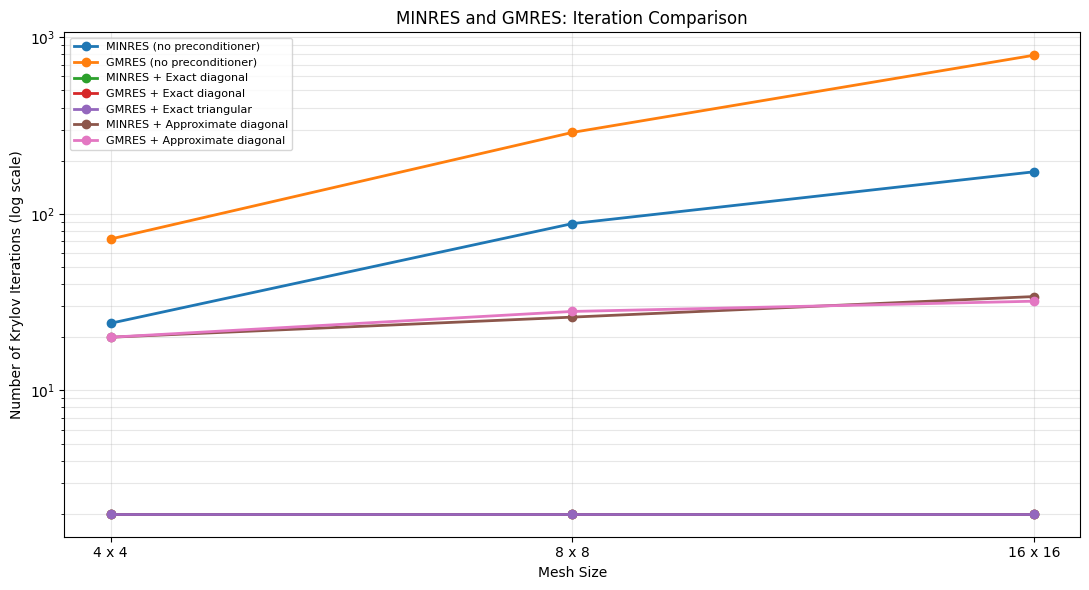

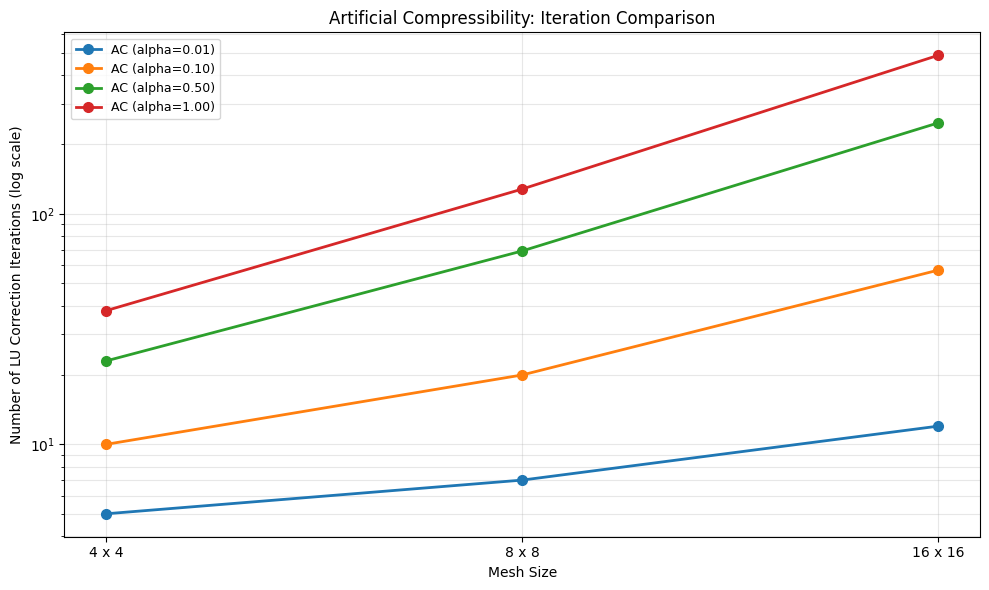

Both iteration comparison graphs generated.
7 Krylov methods and 4 AC parameter values included.
All plotted values are from the verified Step 8 table.


In [39]:

# Step 9: Visual comparison of iteration counts

import matplotlib.pyplot as plt

# Use the verified table from Step 8
plot_df = combined_iterations_df.set_index("Method")

mesh_labels = ["4 x 4", "8 x 8", "16 x 16"]

# --------------------------------------------------
# Graph 1: MINRES and GMRES with preconditioning
# --------------------------------------------------

krylov_methods = [
    "MINRES (no preconditioner)",
    "GMRES (no preconditioner)",
    "MINRES + Exact diagonal",
    "GMRES + Exact diagonal",
    "GMRES + Exact triangular",
    "MINRES + Approximate diagonal",
    "GMRES + Approximate diagonal"
]

plt.figure(figsize=(11, 6))

for method in krylov_methods:
    counts = plot_df.loc[
        method, mesh_labels
    ].to_numpy(dtype=int)

    plt.plot(
        mesh_labels,
        counts,
        marker="o",
        linewidth=2,
        markersize=6,
        label=method
    )

plt.yscale("log")
plt.xlabel("Mesh Size")
plt.ylabel("Number of Krylov Iterations (log scale)")
plt.title(
    "MINRES and GMRES: Iteration Comparison"
)
plt.grid(True, which="both", alpha=0.3)
plt.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Graph 2: Artificial compressibility
# --------------------------------------------------

ac_methods = [
    "AC (alpha=0.01)",
    "AC (alpha=0.10)",
    "AC (alpha=0.50)",
    "AC (alpha=1.00)"
]

plt.figure(figsize=(10, 6))

for method in ac_methods:
    counts = plot_df.loc[
        method, mesh_labels
    ].to_numpy(dtype=int)

    plt.plot(
        mesh_labels,
        counts,
        marker="o",
        linewidth=2,
        markersize=7,
        label=method
    )

plt.yscale("log")
plt.xlabel("Mesh Size")
plt.ylabel("Number of LU Correction Iterations (log scale)")
plt.title(
    "Artificial Compressibility: Iteration Comparison"
)
plt.grid(True, which="both", alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


# Verify the plotted data
assert len(krylov_methods) == 7
assert len(ac_methods) == 4

for method in krylov_methods + ac_methods:
    values = plot_df.loc[
        method, mesh_labels
    ].to_numpy(dtype=float)

    assert np.all(np.isfinite(values))
    assert np.all(values > 0)

print("Both iteration comparison graphs generated.")
print("7 Krylov methods and 4 AC parameter values included.")
print("All plotted values are from the verified Step 8 table.")


### Result

I successfully generated two graphs using the iteration counts from my previous experiments.

### Graph 1: MINRES and GMRES

The first graph compares seven MINRES and GMRES configurations across three mesh sizes.

I observed that the unpreconditioned solvers required more iterations as the mesh size increased.

GMRES without preconditioning had the highest iteration counts among the Krylov methods tested.

The exact block diagonal and exact block triangular preconditioners maintained an iteration count of 2 for all three meshes.

Their lines overlap in the graph because they have the same iteration counts.

The approximate block diagonal preconditioner also reduced the iteration counts compared with the unpreconditioned solvers.

### Graph 2: Artificial Compressibility

The second graph shows the correction iteration counts for four artificial compressibility parameters.

I observed that alpha = 0.01 required the fewest correction iterations for all three meshes.

Alpha = 1.0 required the most correction iterations.

For every fixed alpha value, the iteration count increased with mesh refinement.

On the largest mesh, alpha = 0.01 required 12 corrections, while alpha = 1.0 required 487 corrections.

### Main Observation

These graphs helped me understand how preconditioning and parameter selection affect convergence.

The exact Schur complement preconditioners were very effective at reducing Krylov iterations in my tested systems.

For artificial compressibility, smaller alpha values required fewer correction iterations.

However, Krylov iterations and artificial compressibility corrections involve different computational operations.

Therefore, these graphs do not establish which method has the lowest computation time.

I will compare setup and solve times in the next experiment.


## 10. Computation Time Comparison

### Objective

In this step, I compare the setup, solve, and total computation times of the methods tested in the previous steps.

I want to investigate whether methods with fewer iterations also require less total computation time.

### Methods Included

I will compare:

- Direct solver using sparse LU factorization.
- MINRES and GMRES without preconditioning.
- MINRES and GMRES with exact block diagonal preconditioning.
- GMRES with exact block triangular preconditioning.
- MINRES and GMRES with approximate block diagonal preconditioning.
- Artificial compressibility with four alpha values.

This gives 12 solver configurations, including the direct solver.

### Timing Method

I will use Python's `time.perf_counter()` to measure computation time.

For each method, I will record:

- Setup time.
- Solve time.
- Total time.

The total time is:

$$
T_{\mathrm{total}}
=
T_{\mathrm{setup}}+T_{\mathrm{solve}}
$$

I will repeat every configuration five times and calculate the average computation time.

### Comparison Conditions

I will use the same three Darcy systems:

- 4 × 4 mesh: 88 unknowns.
- 8 × 8 mesh: 336 unknowns.
- 16 × 16 mesh: 1312 unknowns.

All iterative solutions must satisfy the common actual relative residual target of 10⁻⁸.

For MINRES and GMRES, I will reuse the accepted internal tolerances identified in the previous experiments.

I will keep GMRES restart = 20, as used in the earlier steps.

### Important Considerations

The finite element matrix assembly time is excluded.

For Schur complement methods, setup time includes constructing and factorizing the preconditioner.

For artificial compressibility, setup time includes constructing and factorizing the modified matrix using sparse LU.

The direct solver also uses sparse LU factorization.

These measurements depend on my implementation and computational environment. Different methods use different factorization techniques, so this is not an implementation-independent comparison.

I will check the actual relative residual for every timed run before accepting the timing result.


In [40]:

# Step 10: Computation time comparison

timing_repeats = 5

timing_methods = [
    "Direct (sparse LU)"
] + method_order

timing_results = []


def get_saved_rtol(n, method):
    mesh_label = f"{n} x {n}"

    if method == "Direct (sparse LU)" or method.startswith("AC ("):
        return None

    solver = method.split()[0]

    if "no preconditioner" in method:
        df = baseline_df
        row = df[
            (df["Mesh"] == mesh_label)
            & (df["Solver"] == solver)
        ].iloc[0]

    elif method == "GMRES + Exact triangular":
        row = triangular_df[
            triangular_df["Mesh"] == mesh_label
        ].iloc[0]

    elif "Exact diagonal" in method:
        df = exact_diag_df
        row = df[
            (df["Mesh"] == mesh_label)
            & (df["Solver"] == solver)
        ].iloc[0]

    elif "Approximate diagonal" in method:
        df = approx_diag_df
        row = df[
            (df["Mesh"] == mesh_label)
            & (df["Solver"] == solver)
        ].iloc[0]

    else:
        raise ValueError(f"Unknown method: {method}")

    return float(row["Internal rtol"])


def run_timed_method(system, method, internal_rtol):
    A = system["A"]
    D = system["D"]
    G = system["G"]
    b = system["b"]

    b_norm = np.linalg.norm(b)
    M_inv = None
    lu = None

    # --------------------------------------------
    # Measure setup time
    # --------------------------------------------

    setup_start = time.perf_counter()

    if method == "Direct (sparse LU)":
        lu = splu(G.tocsc())

    elif method.endswith("(no preconditioner)"):
        # No preconditioner setup
        pass

    elif "Exact diagonal" in method:
        M_inv = build_exact_diagonal_preconditioner(A, D)

    elif method == "GMRES + Exact triangular":
        M_inv = build_exact_triangular_preconditioner(A, D)

    elif "Approximate diagonal" in method:
        M_inv = build_approx_diagonal_preconditioner(A, D)

    elif method.startswith("AC ("):
        alpha = float(method.split("alpha=")[1].rstrip(")"))

        pressure_dofs = D.shape[0]

        C_alpha = alpha * eye(
            pressure_dofs,
            format="csr"
        )

        G_alpha = bmat(
            [
                [A, -D.T],
                [-D, -C_alpha]
            ],
            format="csc"
        )

        lu = splu(G_alpha)

    else:
        raise ValueError(f"Unknown method: {method}")

    setup_ms = 1000 * (
        time.perf_counter() - setup_start
    )

    # Methods without a preconditioner have no setup
    if method.endswith("(no preconditioner)"):
        setup_ms = 0.0

    # --------------------------------------------
    # Measure solve time
    # --------------------------------------------

    solve_start = time.perf_counter()
    iterations = 0
    info = 0

    if method == "Direct (sparse LU)":
        z = lu.solve(b)

    elif method.startswith("AC ("):
        z = np.zeros_like(b)

        for k in range(1, ac_max_iterations + 1):
            r = b - G @ z

            correction = lu.solve(r)
            z = z + correction
            iterations = k

            actual_residual = (
                np.linalg.norm(b - G @ z) / b_norm
            )

            if actual_residual <= target_residual:
                break

    else:
        iteration_count = [0]

        def count_iteration(value):
            iteration_count[0] += 1

        if method.startswith("MINRES"):
            z, info = minres(
                G,
                b,
                M=M_inv,
                rtol=internal_rtol,
                maxiter=5000,
                callback=count_iteration
            )

        elif method.startswith("GMRES"):
            z, info = gmres(
                G,
                b,
                M=M_inv,
                rtol=internal_rtol,
                atol=0.0,
                restart=20,
                maxiter=500,
                callback=count_iteration,
                callback_type="pr_norm"
            )

        iterations = iteration_count[0]

    # Check the original-system residual
    actual_residual = (
        np.linalg.norm(b - G @ z) / b_norm
    )

    solve_ms = 1000 * (
        time.perf_counter() - solve_start
    )

    if info != 0 or actual_residual > target_residual:
        raise RuntimeError(
            f"{method} failed on a timed run. "
            f"Info={info}, residual={actual_residual:.3e}"
        )

    return {
        "setup_ms": setup_ms,
        "solve_ms": solve_ms,
        "total_ms": setup_ms + solve_ms,
        "iterations": iterations,
        "actual_residual": actual_residual,
        "passed": True
    }


# Run the timing experiments
for n in mesh_sizes:
    system = darcy_systems[n]

    for method in timing_methods:
        internal_rtol = get_saved_rtol(n, method)

        runs = []

        for repeat in range(timing_repeats):
            result = run_timed_method(
                system,
                method,
                internal_rtol
            )
            runs.append(result)

        setup_times = [r["setup_ms"] for r in runs]
        solve_times = [r["solve_ms"] for r in runs]
        total_times = [r["total_ms"] for r in runs]
        residuals = [r["actual_residual"] for r in runs]
        iteration_counts = [r["iterations"] for r in runs]

        timing_results.append({
            "Mesh": f"{n} x {n}",
            "Method": method,
            "Iterations": (
                "—"
                if method == "Direct (sparse LU)"
                else str(iteration_counts[0])
                if len(set(iteration_counts)) == 1
                else f"{min(iteration_counts)}-{max(iteration_counts)}"
            ),
            "Avg setup (ms)": np.mean(setup_times),
            "Avg solve (ms)": np.mean(solve_times),
            "Avg total (ms)": np.mean(total_times),
            "Max residual": max(residuals),
            "Passed runs": sum(r["passed"] for r in runs)
        })


timing_df = pd.DataFrame(timing_results)

print("Computation Time Comparison")
print("---------------------------")

display(
    timing_df.style
    .hide(axis="index")
    .format({
        "Avg setup (ms)": "{:.4f}",
        "Avg solve (ms)": "{:.4f}",
        "Avg total (ms)": "{:.4f}",
        "Max residual": "{:.3e}"
    })
)

# Verify the timing experiment
assert len(timing_df) == 36

assert (timing_df["Passed runs"] == timing_repeats).all()

assert (timing_df["Max residual"] <= target_residual).all()

assert np.allclose(
    timing_df["Avg setup (ms)"]
    + timing_df["Avg solve (ms)"],
    timing_df["Avg total (ms)"]
)

print("\nAll 180 timed runs satisfied the residual target.")
print("36 configurations tested, with 5 repetitions each.")
print("Finite element matrix assembly time was excluded.")


Computation Time Comparison
---------------------------


Mesh,Method,Iterations,Avg setup (ms),Avg solve (ms),Avg total (ms),Max residual,Passed runs
4 x 4,Direct (sparse LU),—,0.6575,0.1168,0.7743,4.945e-16,5
4 x 4,MINRES (no preconditioner),24,0.0000,1.7240,1.7240,4.182e-14,5
4 x 4,GMRES (no preconditioner),72,0.0000,15.6928,15.6928,7.562e-09,5
4 x 4,MINRES + Exact diagonal,2,0.3079,0.4667,0.7745,1.529e-15,5
4 x 4,GMRES + Exact diagonal,2,0.2503,0.6537,0.9039,2.124e-15,5
4 x 4,GMRES + Exact triangular,2,0.2468,0.6499,0.8967,2.161e-15,5
4 x 4,MINRES + Approximate diagonal,20,0.2887,3.1748,3.4635,8.190e-16,5
4 x 4,GMRES + Approximate diagonal,20,0.3999,7.4296,7.8295,2.496e-09,5
4 x 4,AC (alpha=0.01),5,2.3050,0.5672,2.8723,9.547e-10,5
4 x 4,AC (alpha=0.10),10,2.1074,0.8695,2.9769,2.430e-09,5



All 180 timed runs satisfied the residual target.
36 configurations tested, with 5 repetitions each.
Finite element matrix assembly time was excluded.


### Result

I successfully measured the setup, solve, and total computation times of 12 solver configurations on three different mesh sizes.

I repeated each configuration five times, giving a total of 180 timed runs.

All 180 runs satisfied my common actual relative residual target of 10⁻⁸.

### Direct Solver Comparison

I observed that the direct sparse LU solver had the lowest measured total computation time on all three tested meshes.

Its average total times were:

| Mesh Size | Direct Solver Total Time |
|---|---:|
| 4 × 4 | 0.7743 ms |
| 8 × 8 | 1.0160 ms |
| 16 × 16 | 4.5650 ms |

On the 4 × 4 mesh, the direct solver and MINRES with exact diagonal preconditioning had almost identical measured total times: 0.7743 ms and 0.7745 ms, respectively.

This very small difference does not establish a meaningful performance advantage.

### MINRES and GMRES

Without preconditioning, MINRES required less total computation time than GMRES on all three meshes.

For the largest mesh, MINRES required approximately 17.84 ms, while GMRES required approximately 216.79 ms.

### Schur Complement Preconditioners

The exact Schur complement preconditioners reduced the Krylov iteration counts to 2.

However, their total computation times were not always lower than those of the unpreconditioned solvers.

For example, on the 16 × 16 mesh, MINRES with exact block diagonal preconditioning required approximately 213.60 ms in total.

The unpreconditioned MINRES solver required approximately 17.84 ms on the same mesh.

I observed that constructing and factorizing the exact Schur complement introduced a significant setup cost in my dense implementation.

The approximate Schur complement preconditioner also reduced iteration counts, but its measured total times were relatively high on the larger meshes.

### Artificial Compressibility

For the 16 × 16 mesh, artificial compressibility with alpha = 0.01 required approximately 11.29 ms in total.

Alpha = 1.0 required approximately 139.24 ms on the same mesh.

Alpha = 0.01 had the lowest measured total computation time among the artificial compressibility configurations on all three meshes.

For the 8 × 8 mesh, alpha = 0.01 required approximately 5.88 ms, compared with 8.33 ms for alpha = 0.50.

I observed that timing differences did not always follow the iteration counts exactly, particularly on smaller meshes.

### Main Observation

I learned that fewer iterations do not always lead to lower total computation time.

The exact Schur complement preconditioners were effective at reducing Krylov iterations, but their dense setup costs were substantial.

The artificial compressibility method used sparse LU factorization and had different setup and solve costs.

The direct sparse LU solver had the lowest measured total time for all three tested problem sizes, although its result was almost tied with preconditioned MINRES on the smallest mesh.

### Limitations

I excluded finite element matrix assembly time from this comparison.

The methods used different internal operations and factorization techniques.

I also used the accepted internal solver tolerances from the previous experiments, while checking the same actual residual target for every run.

Each timing configuration was repeated five times, but I have not yet analyzed timing variability.

Therefore, these results describe the performance of my current implementations and computational environment. They do not establish which method is universally the fastest.

I will visualize the measured computation times in the next step.

## 11. Visualization of Computation Times

### Objective

In this step, I visualize the computation times measured in Step 10.

My goal is to understand how different methods behave as the mesh size increases and how setup and solve times contribute to the total cost.

### Graph 1: Direct Solver and Krylov Methods

I will compare the average total computation times of:

- Direct sparse LU solver.
- MINRES and GMRES without preconditioning.
- MINRES and GMRES with exact block diagonal preconditioning.
- GMRES with exact block triangular preconditioning.
- MINRES and GMRES with approximate block diagonal preconditioning.

I will use a logarithmic vertical axis to display both small and large computation times clearly.

### Graph 2: Artificial Compressibility

I will compare the average total computation times for four artificial compressibility parameters:

- Alpha = 0.01
- Alpha = 0.10
- Alpha = 0.50
- Alpha = 1.00

This graph will help me understand how parameter selection affects the measured computation time.

### Graph 3: Setup and Solve Time

For the largest mesh (16 × 16), I will create a stacked horizontal bar chart.

Each bar will show:

- Average setup time.
- Average solve time.

The sum of these two values gives the average total computation time.

### Important Considerations

All graphs will use the saved timing data from Step 10.

Each configuration was measured five times.

All timed runs satisfied the common actual relative residual target of 10⁻⁸.

Finite element matrix assembly time was excluded.

The results depend on my implementation and computational environment.

I will use these graphs to study the measured computational costs without claiming that one method is universally the fastest.


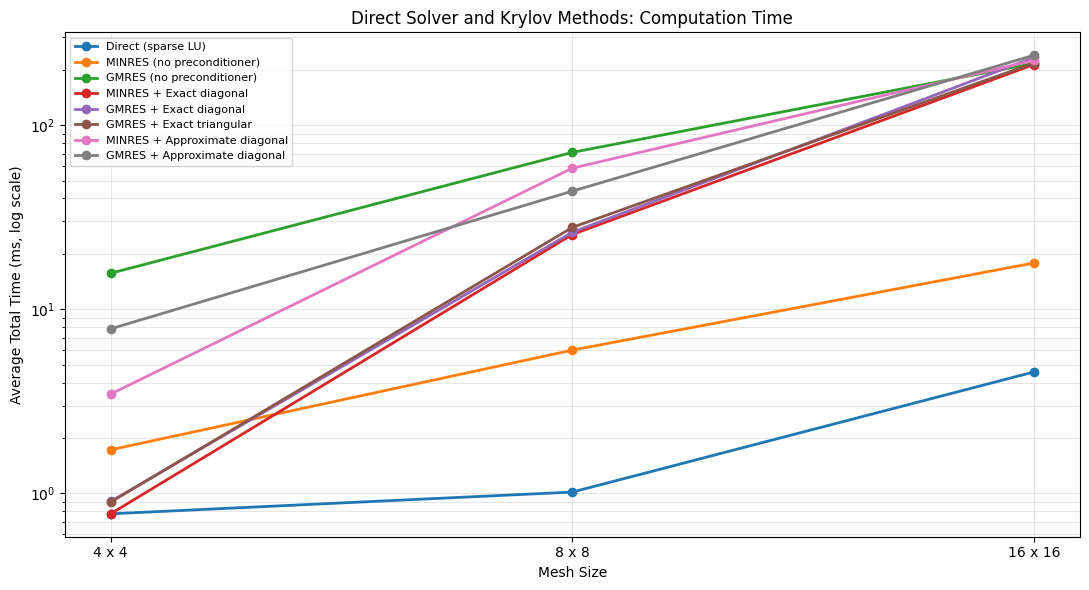

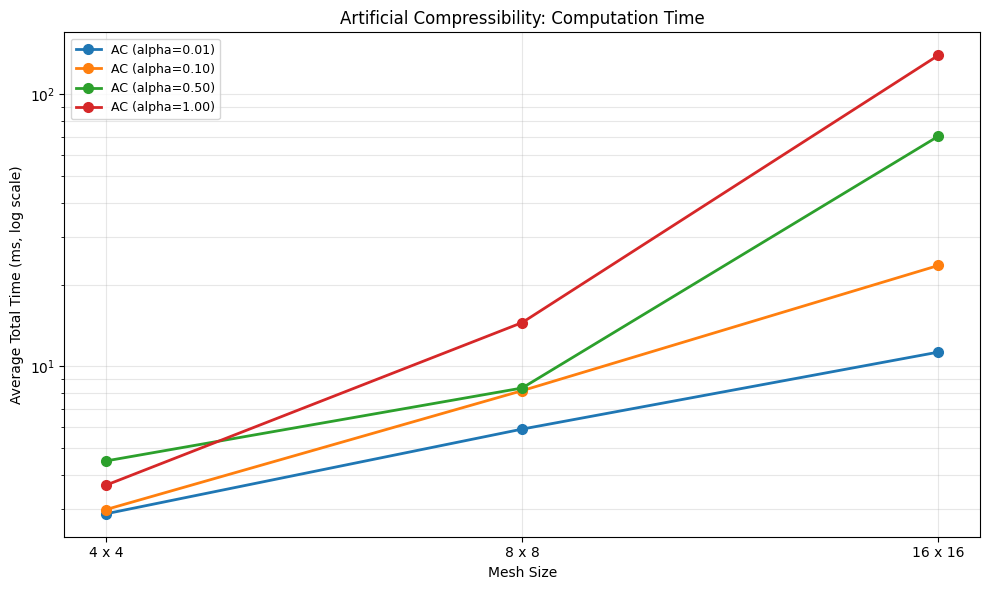

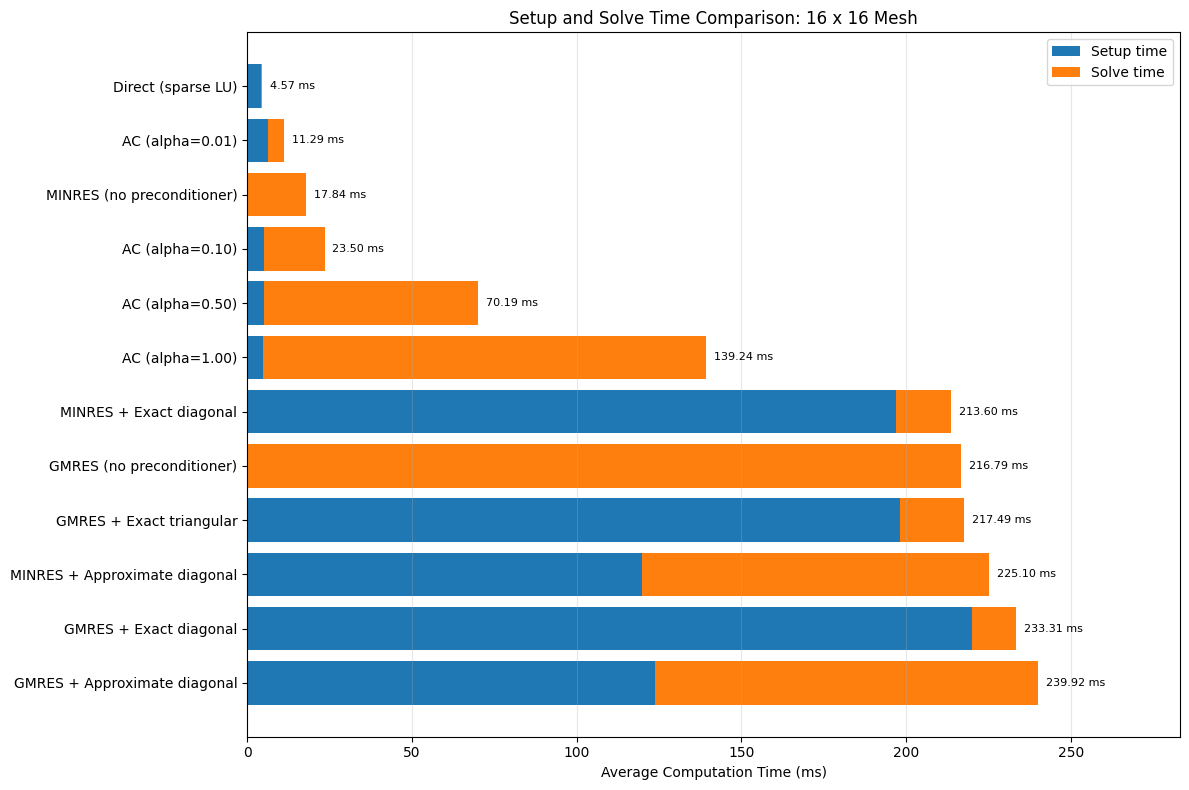

All three computation time graphs generated.
8 direct/Krylov configurations included.
4 artificial compressibility configurations included.
Setup and solve times compared for all 12 methods.
All plotted times are from the saved Step 10 results.


In [41]:

# Step 11: Visual comparison of computation times

import matplotlib.pyplot as plt

mesh_labels = [f"{n} x {n}" for n in mesh_sizes]

# Use the saved timing results from Step 10
total_time_table = timing_df.pivot(
    index="Method",
    columns="Mesh",
    values="Avg total (ms)"
)

# --------------------------------------------------
# Graph 1: Direct solver and Krylov methods
# --------------------------------------------------

krylov_timing_methods = [
    "Direct (sparse LU)"
] + [
    method for method in method_order
    if not method.startswith("AC (")
]

plt.figure(figsize=(11, 6))

for method in krylov_timing_methods:
    times = total_time_table.loc[
        method, mesh_labels
    ].to_numpy(dtype=float)

    plt.plot(
        mesh_labels,
        times,
        marker="o",
        linewidth=2,
        label=method
    )

plt.yscale("log")
plt.xlabel("Mesh Size")
plt.ylabel("Average Total Time (ms, log scale)")
plt.title(
    "Direct Solver and Krylov Methods: Computation Time"
)
plt.grid(True, which="both", alpha=0.3)
plt.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Graph 2: Artificial compressibility timing
# --------------------------------------------------

ac_timing_methods = [
    "AC (alpha=0.01)",
    "AC (alpha=0.10)",
    "AC (alpha=0.50)",
    "AC (alpha=1.00)"
]

plt.figure(figsize=(10, 6))

for method in ac_timing_methods:
    times = total_time_table.loc[
        method, mesh_labels
    ].to_numpy(dtype=float)

    plt.plot(
        mesh_labels,
        times,
        marker="o",
        linewidth=2,
        markersize=7,
        label=method
    )

plt.yscale("log")
plt.xlabel("Mesh Size")
plt.ylabel("Average Total Time (ms, log scale)")
plt.title(
    "Artificial Compressibility: Computation Time"
)
plt.grid(True, which="both", alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Graph 3: Setup vs solve time on largest mesh
# --------------------------------------------------

largest_mesh = "16 x 16"

largest_timing_df = (
    timing_df[
        timing_df["Mesh"] == largest_mesh
    ]
    .sort_values("Avg total (ms)")
    .reset_index(drop=True)
)

methods = largest_timing_df["Method"].tolist()

setup_times = largest_timing_df[
    "Avg setup (ms)"
].to_numpy(dtype=float)

solve_times = largest_timing_df[
    "Avg solve (ms)"
].to_numpy(dtype=float)

total_times = largest_timing_df[
    "Avg total (ms)"
].to_numpy(dtype=float)

positions = np.arange(len(methods))

plt.figure(figsize=(12, 8))

plt.barh(
    positions,
    setup_times,
    label="Setup time"
)

plt.barh(
    positions,
    solve_times,
    left=setup_times,
    label="Solve time"
)

plt.yticks(positions, methods)
plt.gca().invert_yaxis()

plt.xlabel("Average Computation Time (ms)")
plt.title(
    "Setup and Solve Time Comparison: 16 x 16 Mesh"
)
plt.legend()
plt.grid(axis="x", alpha=0.3)

# Display the total time next to each bar
plt.xlim(0, max(total_times) * 1.18)

for i, total in enumerate(total_times):
    plt.text(
        total + max(total_times) * 0.01,
        i,
        f"{total:.2f} ms",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()


# --------------------------------------------------
# Verify the data used in the plots
# --------------------------------------------------

assert len(krylov_timing_methods) == 8
assert len(ac_timing_methods) == 4
assert len(largest_timing_df) == 12

assert np.all(
    np.isfinite(total_time_table.to_numpy(dtype=float))
)

assert np.all(
    total_time_table.to_numpy(dtype=float) > 0
)

assert np.allclose(
    setup_times + solve_times,
    total_times
)

print("All three computation time graphs generated.")
print("8 direct/Krylov configurations included.")
print("4 artificial compressibility configurations included.")
print("Setup and solve times compared for all 12 methods.")
print("All plotted times are from the saved Step 10 results.")

### Result

I successfully generated three graphs using the computation times measured in Step 10.

### Graph 1: Direct Solver and Krylov Methods

The first graph compares the average total computation times of the direct solver and seven Krylov solver configurations.

I observed that the direct sparse LU solver had the lowest measured total time for all three mesh sizes.

For the 16 × 16 mesh, the direct solver required approximately 4.57 ms, while unpreconditioned MINRES required 17.84 ms and unpreconditioned GMRES required 216.79 ms.

On the smallest mesh, the direct solver and MINRES with exact diagonal preconditioning had almost identical measured total times of approximately 0.7743 ms and 0.7745 ms.

The exact Schur complement preconditioners reduced the Krylov iteration counts to 2, but their total computation times were relatively high on the larger meshes.

I observed that constructing and factorizing the preconditioners introduced substantial setup costs in my dense implementation.

### Graph 2: Artificial Compressibility

The second graph compares the average total computation times for four artificial compressibility parameters.

For the 16 × 16 mesh, alpha = 0.01 had the lowest measured total time among the artificial compressibility configurations, approximately 11.29 ms.

Alpha = 1.0 required approximately 139.24 ms on the same mesh.

Alpha = 0.01 also had the lowest measured total time among the artificial compressibility configurations on the 4 × 4 and 8 × 8 meshes.

For the 8 × 8 mesh, alpha = 0.01 required approximately 5.88 ms, while alpha = 0.50 required approximately 8.33 ms.

I observed that the measured computation times were affected by both the number of corrections and the setup cost.

Since I used only five timing repetitions, small timing differences should be interpreted carefully.

### Graph 3: Setup and Solve Time

The third graph shows the average setup and solve times for all 12 methods on the 16 × 16 mesh.

I observed that the exact Schur complement preconditioners had substantial setup costs.

For example, MINRES with exact block diagonal preconditioning required approximately 196.89 ms for setup and 16.71 ms for solving.

In comparison, the direct sparse LU solver required approximately 4.09 ms for setup and 0.48 ms for solving.

Artificial compressibility with alpha = 0.01 required approximately 6.38 ms for setup and 4.91 ms for solving.

The graph helped me understand how different methods distribute their computational costs between setup and solving.

### Main Observation

These graphs helped me understand why fewer iterations do not always mean lower total computation time.

The exact Schur complement preconditioners were effective at reducing Krylov iterations, but their dense setup costs were significant in my implementation.

The direct sparse LU solver had the lowest measured total time for all three tested mesh sizes, although it was almost tied with preconditioned MINRES on the smallest mesh.

However, these results are specific to my current implementation and computational environment.

Matrix assembly time was excluded, and I did not analyze timing variability beyond the five repeated measurements.

Therefore, I cannot conclude that the direct solver is universally faster than the iterative methods.

I will use these observations in the final analysis of my numerical study.

## 12. Final Analysis, Conclusions and Limitations

### Final Overview

In this notebook, I completed a numerical comparison of iterative solvers and preconditioning approaches for a two-dimensional mixed Darcy saddle-point system.

I used RT0 finite elements for flux and P0 elements for pressure.

I tested three mesh sizes, with 88, 336, and 1312 unknowns.

My main goal was to compare convergence, iteration counts, and computational costs under a common actual relative residual target of 10⁻⁸.

### Methods Studied

I compared the following approaches:

- Direct sparse LU solver.
- MINRES and GMRES without preconditioning.
- Exact block diagonal Schur complement preconditioning.
- Exact block triangular Schur complement preconditioning with GMRES.
- Approximate block diagonal Schur complement preconditioning.
- Artificial compressibility iterative correction with four alpha values.

### Convergence Results

I collected iteration counts for 11 iterative configurations across three meshes.

All 33 iterative configurations satisfied the common actual relative residual target of 10⁻⁸.

I observed that MINRES required fewer iterations than GMRES without preconditioning in my experiments.

Both unpreconditioned solvers required more iterations as the mesh was refined.

The exact block diagonal and exact block triangular Schur complement preconditioners reduced the Krylov iteration counts to 2 for every tested mesh.

The approximate block diagonal preconditioner also reduced the iteration counts compared with the unpreconditioned methods.

For artificial compressibility, alpha = 0.01 required the fewest correction iterations for all three mesh sizes.

### Results for the Largest Mesh

The largest tested system contained 1312 unknowns.

| Method | Iterations | Average Total Time |
|---|---:|---:|
| Direct sparse LU | — | 4.57 ms |
| MINRES without preconditioning | 173 | 17.84 ms |
| GMRES without preconditioning | 791 | 216.79 ms |
| MINRES + Exact diagonal | 2 | 213.60 ms |
| GMRES + Exact diagonal | 2 | 233.31 ms |
| GMRES + Exact triangular | 2 | 217.49 ms |
| MINRES + Approximate diagonal | 34 | 225.10 ms |
| GMRES + Approximate diagonal | 32 | 239.92 ms |
| Artificial compressibility, alpha = 0.01 | 12 | 11.29 ms |
| Artificial compressibility, alpha = 0.10 | 57 | 23.50 ms |
| Artificial compressibility, alpha = 0.50 | 248 | 70.19 ms |
| Artificial compressibility, alpha = 1.00 | 487 | 139.24 ms |

The artificial compressibility iteration counts represent LU correction steps, while the MINRES and GMRES iteration counts represent Krylov iterations. They are not equivalent measures of computational work.

### Computation Time Analysis

I measured the setup, solve, and total computation times for 12 configurations across three meshes.

I repeated each configuration five times, giving 180 timed runs.

All 180 runs satisfied the common actual relative residual target of 10⁻⁸.

I observed that the direct sparse LU solver had the lowest measured total time on all three tested meshes.

On the smallest mesh, its total time was approximately 0.7743 ms, compared with 0.7745 ms for MINRES with exact diagonal preconditioning. These measurements were almost identical, so I cannot treat this difference as a meaningful performance advantage.

The exact Schur complement preconditioners were very effective at reducing iteration counts, but their dense matrix construction and factorization introduced substantial setup costs.

For the 16 × 16 mesh, MINRES with exact block diagonal preconditioning required only 2 iterations but approximately 213.60 ms in total.

In comparison, unpreconditioned MINRES required 173 iterations but approximately 17.84 ms.

This showed me that fewer iterations do not always lead to a lower total computation time.

Artificial compressibility with alpha = 0.01 required approximately 11.29 ms on the largest mesh.

Its performance depended on both the number of correction iterations and the cost of sparse LU factorization and solves.

In the final timing run, alpha = 0.01 had the lowest measured total time among the artificial compressibility configurations on all three meshes.

For the 8 × 8 mesh, alpha = 0.01 required approximately 5.88 ms, while alpha = 0.50 required approximately 8.33 ms.

These timing results depend on my implementation and computational environment.

### Main Findings

From these experiments, I learned that:

- Preconditioning can greatly reduce Krylov iteration counts.
- Exact preconditioning can have a substantial setup cost.
- Approximate preconditioning can reduce iteration counts without necessarily reducing total time.
- The artificial compressibility parameter strongly affects convergence.
- Iteration counts alone are not sufficient to compare different numerical methods.
- Setup time, solve time, and the type of operations performed are all important.

### Limitations

This study has several limitations:

- I considered only a two-dimensional Darcy flow problem with constant permeability K = 1.
- I used RT0–P0 finite elements.
- I tested only three mesh sizes, with a maximum of 1312 unknowns.
- I used dense Cholesky factorization for the Schur complement preconditioners.
- I used sparse LU factorization for the direct solver and artificial compressibility method.
- The artificial compressibility method used an algebraic pressure-block modification of the form −αI, rather than a finite element pressure mass matrix.
- The artificial compressibility corrections and Krylov iterations involve different computational operations.
- I used GMRES with restart = 20 and recorded the accepted internal solver tolerances.
- I excluded finite element matrix assembly time from the timing comparison.
- Each timing configuration was repeated five times, but I did not perform a detailed statistical analysis of timing variability.
- I did not investigate much larger systems, variable permeability, or different computational environments.

These limitations mean that my conclusions apply to the tested problem and current implementations.

### What I Learned

This project helped me understand the connection between mixed finite element discretization, saddle-point systems, iterative solvers, and preconditioning.

I learned how to assemble and solve a mixed Darcy system, verify actual residuals, and compare numerical methods under more consistent experimental conditions.

I also learned that a method with very few iterations is not necessarily the method with the lowest total computation time.

Checking the residual of the original system and separating setup costs from solve costs were important parts of my numerical analysis.

### Final Conclusion

In my experiments, the exact Schur complement preconditioners gave the strongest reduction in Krylov iteration counts.

However, their dense setup costs were substantial for the tested problem sizes.

The direct sparse LU solver had the lowest measured total computation time on all three meshes, although its time was almost identical to that of preconditioned MINRES on the smallest mesh.

Artificial compressibility with alpha = 0.01 also gave relatively low measured total times on the largest mesh compared with several iterative configurations.

These observations are specific to my current numerical implementation and should not be interpreted as universal performance rankings.

Overall, I completed a comparative numerical study of iterative solvers and preconditioning approaches for the mixed Darcy saddle-point system, supported by residual checks, iteration tables, and computation time measurements.